# Wood Shear Wall
**SDPWS 2021 (ASD or LRFD) · ASCE 7-22 · NDS 2024**

Segmented wood structural panel shear wall line (blocked, full-height segments). Uses
SDPWS 2021 Table 4.3A nominal unit shear capacity vn (single nominal value for wind and
seismic; ASD vn/2.0 wind and vn/2.8 seismic), specific gravity factor, aspect ratio limit
and adjustment factor, hold-down tension, compression chord (braced by sheathing), and
three-term wall deflection (SDPWS Eq. 4.3-1) with the ASCE 7-22 story drift check.

**How to use:** Run the **Engine** cell once, edit the form fields below, and run **Runtime → Run all** (`Ctrl+F9` / `⌘F9`).

> Design aid only. A licensed engineer must verify all inputs and results.
> Line shears are strength-level values from ASCE 7-22 (Eh includes ρ).

In [1]:
#@title Engine — run this cell first (embedded structcalc library) { display-mode: "form" }
# Unpacks the embedded structcalc library and imports it (no pip install or Drive mount needed).
# Source: structural-calculations (lib/structcalc). Rebuild notebooks with: python build.py
import base64 as _b64, io as _io, os as _os, sys as _sys, tempfile as _tf, zipfile as _zf
_ZIP = (
    "..."
)
_dir = _os.path.join(_tf.gettempdir(), "structcalc_476d0793fd")
if not _os.path.isdir(_os.path.join(_dir, "structcalc")):
    _zf.ZipFile(_io.BytesIO(_b64.b64decode(_ZIP))).extractall(_dir)
for _m in [m for m in _sys.modules if m == "structcalc" or m.startswith("structcalc.")]:
    del _sys.modules[_m]
if _dir not in _sys.path:
    _sys.path.insert(0, _dir)
import structcalc
print(f"structcalc {structcalc.__version__} ready (build 476d0793fd)")

structcalc 0.1.0 ready (build 476d0793fd)


In [2]:
#@title 1. Sheathing and framing
sheathing = "Sheathing 7/16 in. 8d"  #@param ["Structural I 5/16 in. 6d", "Structural I 3/8 in. 8d", "Structural I 7/16 in. 8d", "Structural I 15/32 in. 8d", "Structural I 15/32 in. 10d", "Sheathing 5/16 in. 6d", "Sheathing 3/8 in. 6d", "Sheathing 3/8 in. 8d", "Sheathing 7/16 in. 8d", "Sheathing 15/32 in. 8d", "Sheathing 15/32 in. 10d", "Sheathing 19/32 in. 10d"]
edge_spacing = 4  #@param [6, 4, 3, 2] {type:"raw"}
sides = 1  #@param [1, 2] {type:"raw"}
framing_G = 0.50  #@param {type:"number"}
#@markdown *framing_G*: specific gravity of framing (DF-L 0.50, SP 0.55, Hem-Fir 0.43, SPF 0.42).
vn_override = 0  #@param {type:"number"}
Ga_override = 0  #@param {type:"number"}
#@markdown Overrides per side (`vn` in **plf**, `Ga` in **kips/in**), e.g., for other sheathing types (SDPWS Table 4.3B/4.3C). Enter `0` to use the table.

In [3]:
#@title 2. Wall geometry
height = 9.0  #@param {type:"number"}
segments = "8, 6"  #@param {type:"string"}
aspect_method = "4.3.3.2"  #@param ["4.3.3.2", "2b/h"]
#@markdown *height* and *segments* (comma-separated full-height segment lengths) in **ft**.
#@markdown *aspect_method*: `1.25 − 0.125(h/b)` (SDPWS 4.3.3.2) or `2b/h` (4.3.5.5.1 Exception 1) when h/b > 2.

In [4]:
#@title 3. Loads (strength level)
method = "ASD"  #@param ["ASD", "LRFD"]
Eh = 4.0  #@param {type:"number"}
W = 5.0  #@param {type:"number"}
rho = 1.0  #@param {type:"number"}
sds = 1.0  #@param {type:"number"}
wall_D = 150.0  #@param {type:"number"}
wall_L = 0.0  #@param {type:"number"}
#@markdown *Eh*, *W*: line shears in kip (Eh = ρ·QE). *wall_D / wall_L*: uniform gravity load on the wall in plf.

In [5]:
#@title 4. Chords, hold-downs and drift
chord = "(2)2x4"  #@param {type:"string"}
chord_species = "DF-L"  #@param ["DF-L", "Hem-Fir", "SPF", "Southern Pine"]
chord_grade = "No.2"  #@param ["Select Structural", "No.1", "No.2", "No.3", "Stud"]
chord_trib = 1.0  #@param {type:"number"}
hd_offset = 3.0  #@param {type:"number"}
hd_allow = 3.0  #@param {type:"number"}
hd_defl = 0.12  #@param {type:"number"}
Cd = 4.0  #@param {type:"number"}
Ie = 1.0  #@param {type:"number"}
drift_limit = 0.020  #@param {type:"number"}
#@markdown *chord_trib* (**ft**): gravity tributary length on the end post. *hd_offset* (**in**): wall end to hold-down centroid.
#@markdown *hd_allow* (**kip**): manufacturer hold-down capacity (ASD or LRFD to match *method*). *hd_defl* (**in**): anchorage elongation at drift load.
#@markdown *drift_limit*: ASCE 7-22 Table 12.12-1 drift ratio (0.020 for Risk Category I/II, most structures).

In [6]:
#@title 5. Calculate
from structcalc.calcs import wood_shear_wall

out = wood_shear_wall.run(
    sheathing=sheathing, spacing=int(edge_spacing), sides=int(sides), framing_G=framing_G,
    height=height, segments=segments, method=method, Eh=Eh, W=W, rho=rho, sds=sds,
    wall_D=wall_D, wall_L=wall_L, aspect_method=aspect_method, hd_offset=hd_offset,
    chord=chord, chord_species=chord_species, chord_grade=chord_grade, chord_trib=chord_trib,
    hd_allow=hd_allow, hd_defl=hd_defl, Cd=Cd, Ie=Ie, drift_limit=drift_limit,
    vn_override=vn_override, Ga_override=Ga_override,
)
out["report"].show()

findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


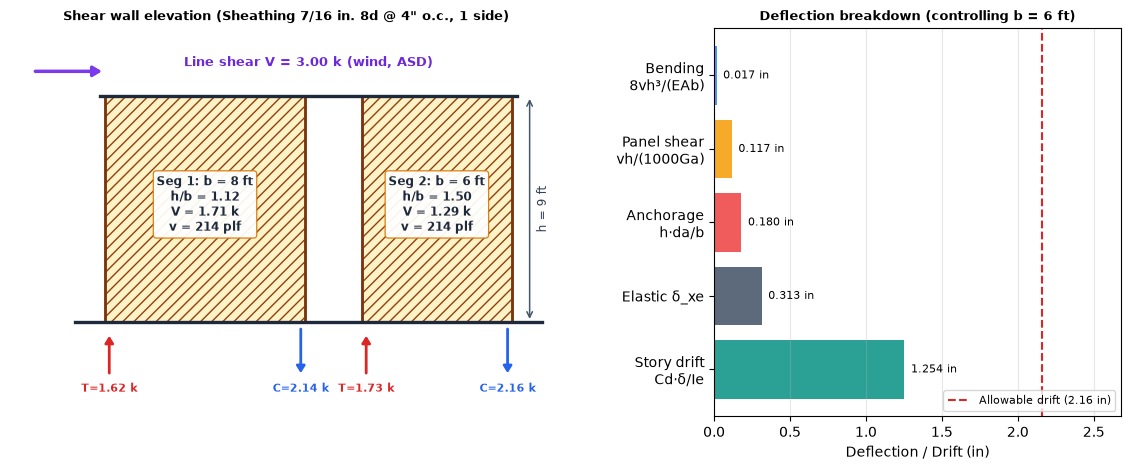

In [7]:
#@title 6. Wall elevation and deflection breakdown
fig = wood_shear_wall.plot(out)

In [8]:
#@title 7. Save report as HTML (optional)
save_report = False  #@param {type:"boolean"}
if save_report:
    path = out["report"].save_html("wood_shear_wall.html")
    print("saved", path)
    try:
        from google.colab import files
        files.download(path)
    except ImportError:
        pass